# BERT ve T5: Mimari İnceleme ve Uygulamalar

Bu çalışma, BERT (Devlin ve ark., 2019) ve T5 (Raffel ve ark., 2020) modellerinin mimarisini ve ön eğitim
hedeflerini önceden eğitilmiş modeller üzerinde incelemektedir.

**İçerik**
1. BERT mimarisi: yapılandırma, parametre dağılımı, tensör boyutları
2. Öz-dikkat mekanizmasının elle hesaplanması ve doğrulanması
3. Maskeli dil modellemesi ve çift yönlü bağlam
4. Bağlamsal kelime temsilleri
5. T5 mimarisi: encoder, decoder ve paylaşılan gömme
6. Otoregresif çözümleme (greedy decoding)
7. Span corruption ön eğitim hedefi
8. Metinden metne çok görevli kullanım (FLAN-T5)

**Kullanılan modeller**

| Model | Hugging Face kimliği | Parametre |
| --- | --- | --- |
| BERTurk (BERT-Base, Türkçe) | `dbmdz/bert-base-turkish-cased` | ~110M |
| T5-Small | `google-t5/t5-small` | ~60M |
| FLAN-T5-Base | `google/flan-t5-base` | ~250M |

## 0. Ortam

In [1]:
!pip install -q --disable-pip-version-check transformers sentencepiece ipywidgets

In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers
from transformers import (
    AutoModel,
    AutoModelForSeq2SeqLM,
    AutoTokenizer,
    PreTrainedModel,
    PreTrainedTokenizerBase,
    pipeline,
)

BERT_ID = "dbmdz/bert-base-turkish-cased"
T5_ID = "google-t5/t5-small"
FLAN_ID = "google/flan-t5-base"

# Model yükleme raporlarını ve ilerleme çubuklarını gizle
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()

torch.manual_seed(42)
torch.set_grad_enabled(False)

print(f"torch {torch.__version__} | transformers {transformers.__version__}")

torch 2.15.0+cpu | transformers 5.22.1


## 1. BERT Mimarisi

BERT-Base, L = 12 encoder bloğu, H = 768 gizli boyut ve A = 12 dikkat başından oluşur.
Her blok çok başlı öz-dikkat ve konum bazlı ileri beslemeli ağ (FFN) alt katmanlarını içerir.
Aşağıda yapılandırma değerleri ve parametrelerin bileşenlere dağılımı modelden okunmaktadır.

In [3]:
bert_tok = AutoTokenizer.from_pretrained(BERT_ID)
bert = AutoModel.from_pretrained(BERT_ID, attn_implementation="eager").eval()

cfg = bert.config
print(f"L = {cfg.num_hidden_layers}, H = {cfg.hidden_size}, A = {cfg.num_attention_heads}, "
      f"d_k = {cfg.hidden_size // cfg.num_attention_heads}, d_ff = {cfg.intermediate_size}, "
      f"sözlük = {cfg.vocab_size}, maks. konum = {cfg.max_position_embeddings}")


def count_params(model: torch.nn.Module, prefix: str = "") -> int:
    """Adı verilen önekle başlayan parametrelerin toplam sayısı."""
    return sum(p.numel() for name, p in model.named_parameters() if name.startswith(prefix))


block = "encoder.layer.0."
breakdown = {
    "Gömme katmanı": count_params(bert, "embeddings."),
    "Öz-dikkat (1 blok)": count_params(bert, block + "attention."),
    "FFN (1 blok)": count_params(bert, block + "intermediate.") + count_params(bert, block + "output."),
    f"Encoder ({cfg.num_hidden_layers} blok)": count_params(bert, "encoder."),
    "Pooler": count_params(bert, "pooler."),
    "Toplam": count_params(bert),
}
for name, n in breakdown.items():
    print(f"{name:<22}{n / 1e6:>8.2f} M")

L = 12, H = 768, A = 12, d_k = 64, d_ff = 3072, sözlük = 32000, maks. konum = 512
Gömme katmanı            24.97 M
Öz-dikkat (1 blok)        2.36 M
FFN (1 blok)              4.72 M
Encoder (12 blok)        85.05 M
Pooler                    0.59 M
Toplam                  110.62 M


In [4]:
sentence = "Çay kenarında çay içtik."
enc = bert_tok(sentence, return_tensors="pt")
tokens = bert_tok.convert_ids_to_tokens(enc["input_ids"][0])

out = bert(**enc, output_hidden_states=True, output_attentions=True)

print("Tokenler            :", tokens)
print("Gömme çıktısı       :", tuple(out.hidden_states[0].shape))
print("Son katman çıktısı  :", tuple(out.last_hidden_state.shape))
print("Dikkat ağırlıkları  :", tuple(out.attentions[0].shape), "(batch, baş, n, n)")
print("Katman sayısı       :", len(out.attentions))

Tokenler            : ['[CLS]', 'Çay', 'kenarında', 'çay', 'iç', '##tik', '.', '[SEP]']
Gömme çıktısı       : (1, 8, 768)
Son katman çıktısı  : (1, 8, 768)
Dikkat ağırlıkları  : (1, 12, 8, 8) (batch, baş, n, n)
Katman sayısı       : 12


## 2. Öz-Dikkat Mekanizmasının Doğrulanması

Ölçeklenmiş nokta çarpımı dikkati (Vaswani ve ark., 2017):

$$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V$$

İlk encoder bloğunun girdisi kullanılarak tek bir dikkat başının ağırlıkları elle hesaplanmakta ve
modelin döndürdüğü ağırlıklarla karşılaştırılmaktadır.

In [5]:
def manual_attention(x: torch.Tensor, layer: torch.nn.Module, head: int, d_k: int) -> torch.Tensor:
    """Bir BERT öz-dikkat katmanında tek bir başın dikkat ağırlıklarını hesaplar."""
    cols = slice(head * d_k, (head + 1) * d_k)
    q = layer.query(x)[:, cols]
    k = layer.key(x)[:, cols]
    scores = q @ k.T / d_k ** 0.5
    return scores.softmax(dim=-1)


d_k = cfg.hidden_size // cfg.num_attention_heads
x0 = out.hidden_states[0][0]
self_attn = bert.encoder.layer[0].attention.self

max_err = max(
    (manual_attention(x0, self_attn, h, d_k) - out.attentions[0][0, h]).abs().max().item()
    for h in range(cfg.num_attention_heads)
)
print(f"12 baş için maksimum mutlak fark: {max_err:.2e}")

12 baş için maksimum mutlak fark: 0.00e+00


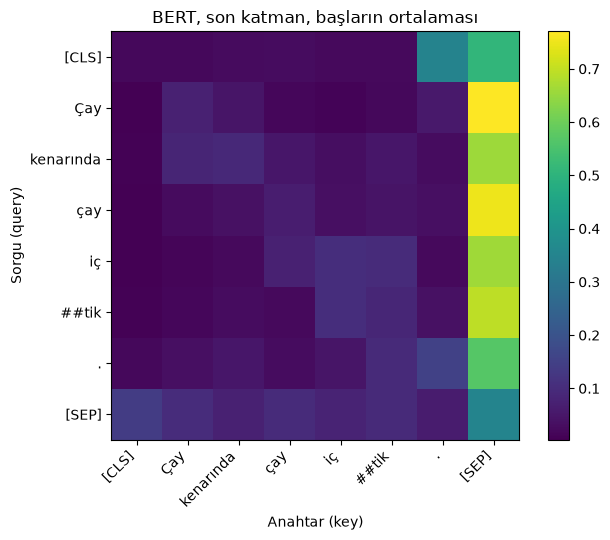

In [6]:
def plot_attention(weights: torch.Tensor, x_labels: list[str], y_labels: list[str], title: str) -> None:
    fig, ax = plt.subplots(figsize=(0.6 * len(x_labels) + 2, 0.5 * len(y_labels) + 1.5))
    im = ax.imshow(weights, cmap="viridis")
    ax.set_xticks(range(len(x_labels)), x_labels, rotation=45, ha="right")
    ax.set_yticks(range(len(y_labels)), y_labels)
    ax.set_xlabel("Anahtar (key)")
    ax.set_ylabel("Sorgu (query)")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    plt.show()


plot_attention(out.attentions[-1][0].mean(dim=0), tokens, tokens,
               "BERT, son katman, başların ortalaması")

## 3. Maskeli Dil Modellemesi ve Çift Yönlü Bağlam

BERT, girdideki tokenlerin %15'inin maskelendiği MLM hedefiyle ön eğitilmiştir. Aşağıdaki ikinci deneyde
iki cümlenin maskeden önceki kısmı aynıdır; yalnızca maskeden sonraki fiil farklıdır. Tahminlerin değişmesi,
modelin sağ bağlamı da kullandığını gösterir.

In [7]:
fill_mask = pipeline("fill-mask", model=BERT_ID)


def top_predictions(text: str, k: int = 5) -> list[tuple[str, float]]:
    return [(r["token_str"], round(r["score"], 3)) for r in fill_mask(text, top_k=k)]


for text in [
    "Türkiye'nin başkenti [MASK]'dır.",
    "Kahvaltıda sıcak bir [MASK] içtim.",
    "Kahvaltıda sıcak bir [MASK] yedim.",
]:
    print(f"{text}\n  {top_predictions(text)}")

Türkiye'nin başkenti [MASK]'dır.
  [('Ankara', 0.842), ('Antalya', 0.025), ('Diyarbakır', 0.024), ('Bursa', 0.01), ('Lefkoşa', 0.006)]
Kahvaltıda sıcak bir [MASK] içtim.
  [('şeyler', 0.585), ('kahve', 0.127), ('çay', 0.111), ('şey', 0.058), ('çorba', 0.028)]
Kahvaltıda sıcak bir [MASK] yedim.
  [('şeyler', 0.478), ('yemek', 0.198), ('sandviç', 0.13), ('çorba', 0.038), ('ekmek', 0.017)]


## 4. Bağlamsal Kelime Temsilleri

Statik gömmelerde (Word2Vec vb.) bir kelimenin tek bir vektörü vardır. BERT'te ise vektör bağlama göre değişir.
"çay" kelimesinin "akarsu" ve "içecek" anlamlarındaki son katman temsilleri kosinüs benzerliğiyle karşılaştırılmaktadır.

In [8]:
def word_vector(text: str, word: str) -> torch.Tensor:
    """Kelimenin son katman temsilini döndürür; alt parçalara bölünmüşse ortalamasını alır."""
    enc = bert_tok(text, return_tensors="pt")
    hidden = bert(**enc).last_hidden_state[0]
    target = bert_tok(word, add_special_tokens=False)["input_ids"]
    ids = enc["input_ids"][0].tolist()
    for i in range(len(ids) - len(target) + 1):
        if ids[i:i + len(target)] == target:
            return hidden[i:i + len(target)].mean(dim=0)
    raise ValueError(f"'{word}' bulunamadı: {text}")


samples = {
    "akarsu-1": "Dün çay kenarında piknik yaptık.",
    "akarsu-2": "Akşam çay kenarında yürüyüş yaptık.",
    "içecek-1": "Kahvaltıda bir bardak çay içtim.",
    "içecek-2": "Misafirlere demli çay ikram ettik.",
}
vecs = F.normalize(torch.stack([word_vector(t, "çay") for t in samples.values()]), dim=1)
sim = vecs @ vecs.T

labels = list(samples)
print(" " * 10 + "".join(f"{l:>10}" for l in labels))
for label, row in zip(labels, sim):
    print(f"{label:<10}" + "".join(f"{v:>10.3f}" for v in row))

            akarsu-1  akarsu-2  içecek-1  içecek-2
akarsu-1       1.000     0.918     0.754     0.746
akarsu-2       0.918     1.000     0.688     0.678
içecek-1       0.754     0.688     1.000     0.902
içecek-2       0.746     0.678     0.902     1.000


## 5. T5 Mimarisi

T5, encoder ve decoder yığınlarından oluşan bir Transformer'dır. Decoder blokları, encoder bloklarından farklı
olarak encoder çıktısına bakan bir çapraz dikkat alt katmanı içerir. Konum bilgisi mutlak gömmelerle değil,
dikkat skorlarına eklenen göreli konum yanlılıklarıyla verilir. Gömme matrisi encoder, decoder ve çıktı
katmanı arasında paylaşılır.

In [9]:
t5_tok = AutoTokenizer.from_pretrained(T5_ID)
t5 = AutoModelForSeq2SeqLM.from_pretrained(T5_ID).eval()

c = t5.config
print(f"encoder blok = {c.num_layers}, decoder blok = {c.num_decoder_layers}, d_model = {c.d_model}, "
      f"d_ff = {c.d_ff}, baş = {c.num_heads}, d_kv = {c.d_kv}")
print(f"göreli konum: {c.relative_attention_num_buckets} kova, maks. mesafe {c.relative_attention_max_distance}, "
      f"aktivasyon = {c.feed_forward_proj}")

shared = t5.shared.weight.numel()
print(f"Paylaşılan gömme : {shared / 1e6:6.2f} M")
print(f"Encoder blokları : {(count_params(t5.encoder) - shared) / 1e6:6.2f} M")
print(f"Decoder blokları : {(count_params(t5.decoder) - shared) / 1e6:6.2f} M")
print(f"Toplam           : {count_params(t5) / 1e6:6.2f} M")

encoder blok = 6, decoder blok = 6, d_model = 512, d_ff = 2048, baş = 8, d_kv = 64
göreli konum: 32 kova, maks. mesafe 128, aktivasyon = relu
Paylaşılan gömme :  16.45 M
Encoder blokları :  18.88 M
Decoder blokları :  25.18 M
Toplam           :  60.51 M


## 6. Otoregresif Çözümleme

Encoder girdiyi bir kez işler. Decoder başlangıç tokeniyle başlar ve her adımda en olası tokeni seçerek
diziye ekler (greedy decoding). Elle yazılan döngünün sonucu `generate()` ile karşılaştırılmaktadır.

In [10]:
def greedy_decode(model: PreTrainedModel, tok: PreTrainedTokenizerBase, text: str,
                  max_new_tokens: int = 20) -> list[str]:
    """Her adımda decoder girdisini döndürerek greedy çözümleme yapar."""
    enc = tok(text, return_tensors="pt")
    encoder_out = model.encoder(**enc)
    dec = torch.tensor([[model.config.decoder_start_token_id]])
    steps = []
    for _ in range(max_new_tokens):
        logits = model(encoder_outputs=encoder_out, attention_mask=enc["attention_mask"],
                       decoder_input_ids=dec).logits
        next_id = logits[0, -1].argmax().view(1, 1)
        dec = torch.cat([dec, next_id], dim=1)
        steps.append(tok.decode(dec[0], skip_special_tokens=True))
        if next_id.item() == tok.eos_token_id:
            break
    return steps


source = "translate English to German: That is good."
for i, s in enumerate(greedy_decode(t5, t5_tok, source), 1):
    print(f"adım {i:>2}: {s}")

reference = t5.generate(**t5_tok(source, return_tensors="pt"), max_new_tokens=20)
print("generate():", t5_tok.decode(reference[0], skip_special_tokens=True))

adım  1: Das
adım  2: Das ist
adım  3: Das ist gut
adım  4: Das ist gut.
adım  5: Das ist gut.
generate(): Das ist gut.


## 7. Span Corruption

T5'in ön eğitim hedefinde girdideki ardışık token grupları tek bir sentinel tokenle (`<extra_id_i>`)
değiştirilir; hedef dizi yalnızca çıkarılan grupları içerir.

In [11]:
def span_corrupt(words: list[str], spans: list[tuple[int, int]]) -> tuple[str, str]:
    """Verilen [başlangıç, bitiş) aralıklarından (girdi, hedef) çifti üretir."""
    source, target, prev = [], [], 0
    for i, (start, end) in enumerate(spans):
        source += words[prev:start] + [f"<extra_id_{i}>"]
        target += [f"<extra_id_{i}>"] + words[start:end]
        prev = end
    return " ".join(source + words[prev:]), " ".join(target + [f"<extra_id_{len(spans)}>"])


src, tgt = span_corrupt("Thank you for inviting me to your party last week .".split(), [(2, 4), (8, 9)])
print("girdi :", src)
print("hedef :", tgt)

pred = t5.generate(**t5_tok(src, return_tensors="pt"), max_new_tokens=20)
print("model :", t5_tok.decode(pred[0], skip_special_tokens=False))

girdi : Thank you <extra_id_0> me to your party <extra_id_1> week .
hedef : <extra_id_0> for inviting <extra_id_1> last <extra_id_2>


model : <pad>. Thank you for inviting<extra_id_1> this<extra_id_2>.</s>


## 8. Metinden Metne Çok Görevli Kullanım

T5 tüm görevleri metin girdisi ve metin çıktısı olarak ele alır. Orijinal T5 görev öneklerine
(`translate`, `summarize`, `cola sentence`) göre çalışır; talimatla ince ayarlanmış FLAN-T5 ise doğal dil
talimatlarını izler. Aynı girdiler iki modele verilmektedir.

In [12]:
flan_tok = AutoTokenizer.from_pretrained(FLAN_ID)
flan = AutoModelForSeq2SeqLM.from_pretrained(FLAN_ID).eval()


def generate(model: PreTrainedModel, tok: PreTrainedTokenizerBase, text: str, max_new_tokens: int = 40) -> str:
    ids = model.generate(**tok(text, return_tensors="pt"), max_new_tokens=max_new_tokens)
    return tok.decode(ids[0], skip_special_tokens=True)


prompts = [
    "translate English to German: How old are you?",
    "cola sentence: The students is happy.",
    "summarize: The university library will stay open 24 hours a day during finals week. "
    "Students can use the study rooms at any time.",
    "Is this review positive or negative? Review: Terrible battery life.",
    "Answer the question: What is the capital of Turkey?",
]
for p in prompts:
    print(p)
    print(f"  T5-Small : {generate(t5, t5_tok, p)}")
    print(f"  FLAN-T5  : {generate(flan, flan_tok, p)}")

translate English to German: How old are you?
  T5-Small : Wie alt sind Sie?


  FLAN-T5  : Wie old sind Sie?
cola sentence: The students is happy.
  T5-Small : acceptable


  FLAN-T5  : The students is drinking cola.
summarize: The university library will stay open 24 hours a day during finals week. Students can use the study rooms at any time.


  T5-Small : the university library will stay open 24 hours a day during finals week. students can use the study rooms at any time.


  FLAN-T5  : The library will be open from 8:00 a.m. to 5:00 p.m. on Friday and Saturday.
Is this review positive or negative? Review: Terrible battery life.
  T5-Small : Review: Review: Terrible battery life.


  FLAN-T5  : negative
Answer the question: What is the capital of Turkey?
  T5-Small : Turkey: What is the capital of Turkey?


  FLAN-T5  : tbilisi


## Kaynaklar

- Devlin, J., Chang, M.-W., Lee, K., Toutanova, K. (2019). BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding. *NAACL-HLT*.
- Raffel, C. ve ark. (2020). Exploring the Limits of Transfer Learning with a Unified Text-to-Text Transformer. *JMLR*, 21(140).
- Vaswani, A. ve ark. (2017). Attention Is All You Need. *NeurIPS*.
- Chung, H. W. ve ark. (2022). Scaling Instruction-Finetuned Language Models. *arXiv:2210.11416*.
- Schweter, S. (2020). BERTurk: BERT models for Turkish. Zenodo.